In [30]:
from transformers import AutoImageProcessor, AutoModelForImageClassification
from PIL import Image
import torch 
import os
import numpy as np
from torch.utils.data import DataLoader
from torchvision import transforms
import pandas as pd
from sklearn.model_selection import train_test_split
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import fastparquet
from sklearn.metrics import classification_report

In [31]:
train_path = "hagrid-sample-30k-384p/hagrid_30k"
folders = sorted(
    f for f in os.listdir(train_path)
    if os.path.isdir(os.path.join(train_path, f))
)[:4]

List_of_files = []
labels = []

for folder in folders:
    folder_path = f"hagrid-sample-30k-384p/hagrid_30k/{folder}"

    for file in os.listdir(folder_path)[500:700]:
        folder_file_path = f"{folder_path}/{file}"
        List_of_files.append(folder_file_path)
        labels.append(folder)


X=pd.DataFrame(List_of_files, columns=["file_path"])
y=pd.DataFrame(labels, columns=["label"])
label_to_id = {name: idx for idx, name in enumerate(sorted(y["label"].unique()))}
y["label"] = y["label"].map(label_to_id)



In [32]:
model = AutoModelForImageClassification.from_pretrained(
    "./best_model",
    local_files_only=True
)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 192, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0-11): 12 x ViTLayer(
        (attention): ViTAttention(
          (q_proj): Linear(in_features=192, out_features=192, bias=True)
          (k_proj): Linear(in_features=192, out_features=192, bias=True)
          (v_proj): Linear(in_features=192, out_features=192, bias=True)
          (o_proj): Linear(in_features=192, out_features=192, bias=True)
        )
        (layernorm_before): LayerNorm((192,), eps=1e-12, elementwise_affine=True)
        (layernorm_after): LayerNorm((192,), eps=1e-12, elementwise_affine=True)
        (mlp): ViTMLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=192, out_features=768, bias=True)
          (fc2): Linear(in_features=768, out_f

In [33]:
class CachedImageDataset(torch.utils.data.Dataset):
    def __init__(self, dt, dl, transform=None):
        self.data = []
        self.labels = dl
        self.dt = dt
        self.transform = transform


        for i in range(len(self.dt)):
            path = self.dt[i]
            img = Image.open(path).convert("RGB")
   
            label = torch.tensor(self.labels[i], dtype=torch.long)
            self.data.append((img, label))

            

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        img, label = self.data[index]

        if self.transform:
            img = self.transform(img)

        return img, label

In [34]:
#test model

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5],
    ),
])




test_dataset = CachedImageDataset(X["file_path"].tolist(), y["label"].tolist(), transform=test_transform)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)
total_correct=0
total_samples=0

from sklearn.metrics import classification_report, ConfusionMatrixDisplay

class_names = [
    name.replace("train_val_", "")
    for name, class_id in sorted(label_to_id.items(), key=lambda x: x[1])
]

all_true = []
all_predictions = []
all_confidences = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        output = model(pixel_values=images)
        probabilities = torch.softmax(output.logits, dim=1)
        confidences, predictions = probabilities.max(dim=1)

        all_true.extend(labels.tolist())
        all_predictions.extend(predictions.cpu().tolist())
        all_confidences.extend(confidences.cpu().tolist())

In [35]:
report = classification_report(
    all_true,
    all_predictions,
    labels=range(len(class_names)),
    target_names=class_names,
    digits=3,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()
display(report_df)

,precision,recall,f1-score,support
call,0.748744,0.74500,0.746867,200.00000
dislike,0.871951,0.71500,0.785714,200.00000
fist,0.673554,0.81500,0.737557,200.00000
four,0.810256,0.79000,0.800000,200.00000
accuracy,0.766250,0.76625,0.766250,0.76625
macro avg,0.776126,0.76625,0.767535,800.00000
weighted avg,0.776126,0.76625,0.767535,800.00000


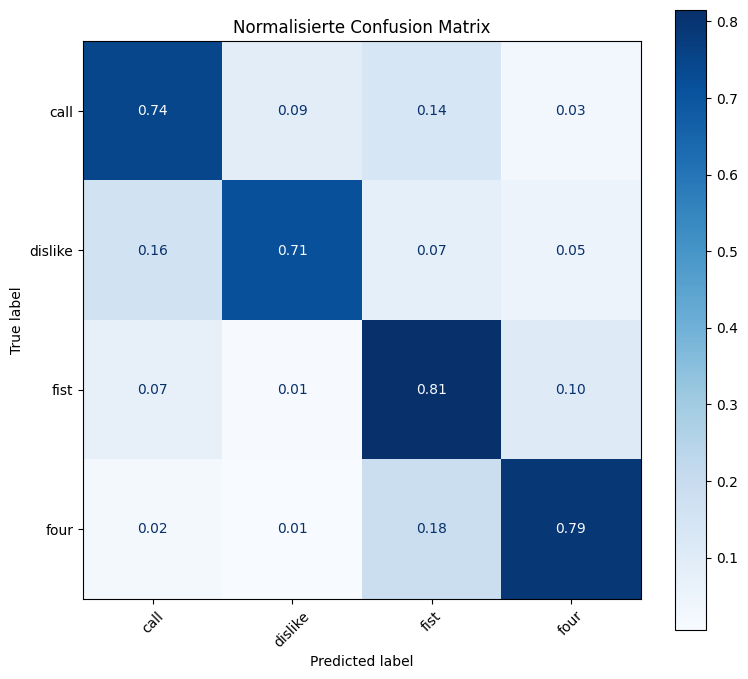

In [36]:
fig, ax = plt.subplots(figsize=(8, 7))

ConfusionMatrixDisplay.from_predictions(
    all_true,
    all_predictions,
    labels=range(len(class_names)),
    display_labels=class_names,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Normalisierte Confusion Matrix")
plt.tight_layout()
plt.show()

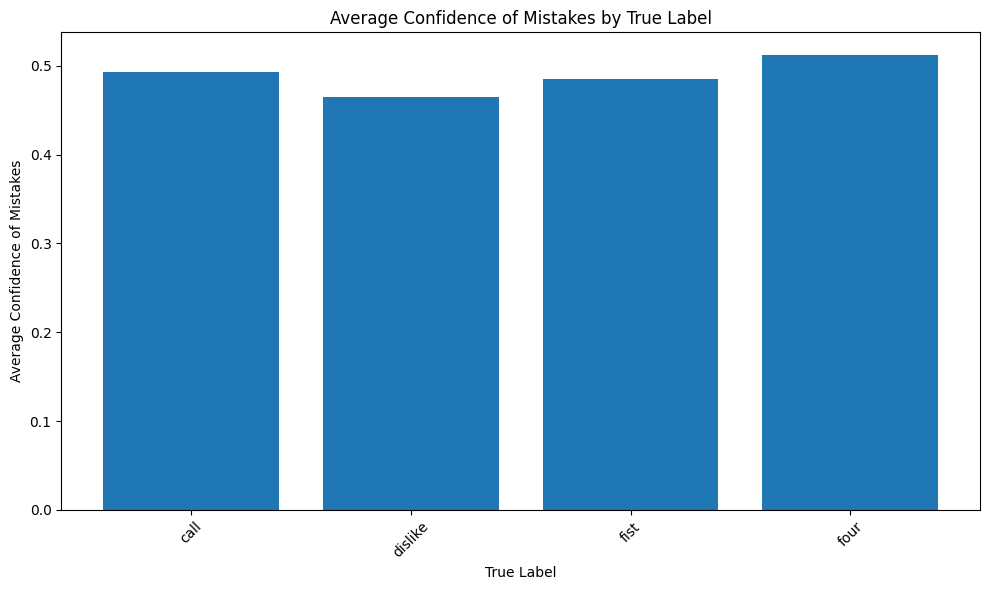

In [ ]:
results = pd.DataFrame({
    "file_path": X["file_path"].tolist(),
    "true_id": all_true,
    "predicted_id": all_predictions,
    "confidence": all_confidences
})

results["true_label"] = results["true_id"].map(
    dict(enumerate(class_names))
)
results["predicted_label"] = results["predicted_id"].map(
    dict(enumerate(class_names))
)
results["correct"] = results["true_id"] == results["predicted_id"]

mistakes = results[~results["correct"]].sort_values(
    "confidence",
    ascending=False
)

mistakes_grouped=mistakes.groupby("true_label")["confidence"].mean().reset_index()

plt.figure(figsize=(10, 6))
plt.bar(
    mistakes_grouped["true_label"],
    mistakes_grouped["confidence"]
)
plt.xlabel("True Label")
plt.ylabel("Average Confidence of Mistakes")
plt.title("Average Confidence of Mistakes by True Label")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


